# E4: CNN | 128 Mel bins | có SpecAugment
Nhánh GitHub: `07-E4-cnn-mel128-specaug`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [2]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [3]:
EXP_ID = "E4"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'cnn', 'n_mels': 128, 'specaug': True}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [4]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E4 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7667


train:   0%|          | 0/40 [00:00<?, ?it/s]

E4 {'LR': 0.001, 'EPOCHS': 40} -> 0.7911


,LR,EPOCHS,val_macro_f1,best_epoch
1,0.0010,40,0.791126,36
0,0.0003,40,0.766744,36


E4: learning rate được chọn = 0.001


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [5]:
runs, rob = run_exp(EXP_ID, lr)

E4 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E4 | fold 1] acc 0.8325 | macro-F1 0.8247 | lr 0.001 | epoch tốt nhất 79 | 180s


E4 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E4 | fold 2] acc 0.8325 | macro-F1 0.8280 | lr 0.001 | epoch tốt nhất 76 | 180s


E4 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E4 | fold 3] acc 0.8525 | macro-F1 0.8472 | lr 0.001 | epoch tốt nhất 75 | 182s


E4 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E4 | fold 4] acc 0.8350 | macro-F1 0.8329 | lr 0.001 | epoch tốt nhất 65 | 182s


E4 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E4 | fold 5] acc 0.7925 | macro-F1 0.7841 | lr 0.001 | epoch tốt nhất 71 | 181s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.8325,0.8247,0.001,79,0.8315,180.1002
1,2,0.8325,0.8280,0.001,76,0.8648,179.9282
2,3,0.8525,0.8472,0.001,75,0.8406,181.5234
3,4,0.8350,0.8329,0.001,65,0.8252,181.6867
4,5,0.7925,0.7841,0.001,71,0.8512,180.5042


E4: Accuracy 82.90 ± 2.21 | Macro-F1 82.34 ± 2.36 | 1,185,490 tham số


,acc,macro_f1
condition,,
Sạch,82.90,82.34
20 dB,68.80,68.51
10 dB,41.45,42.99
0 dB,8.70,7.27


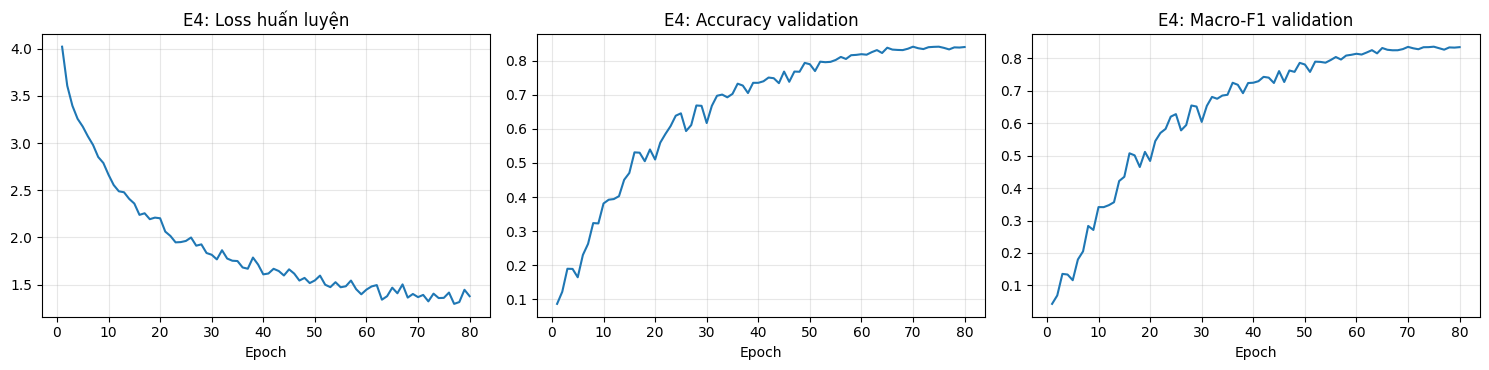

In [6]:
show_exp(EXP_ID)